# DRP TASK 1  
Learn how to download and load financial market data using either R or Python.  
Obtain at least one dataset of daily prices and one dataset of intraday prices (for example, at one-minute or five-minute intervals).  
Calculate logarithmic returns and produce plots of their evolution through time.  
Pay attention to missing observations, trading hours, and the differences between daily and intraday data.  
You may use the same asset at both frequencies.  


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('Successfully imported')

Successfully imported


In [23]:
AAPL_daily=pd.read_csv('AAPL_daily.csv',sep=';')
AAPL_daily.head(5)
AAPL_intraday=pd.read_csv('AAPL_intraday.csv',sep=';')
AAPL_intraday.head(5)

,datetime,open,high,low,close,volume
0,2026-11-16 15:55:00,352.01001,353.00000,351.35001,352.810000,2873163
1,2026-11-16 15:50:00,351.82001,352.48001,351.70001,352.070007,928027
2,2026-11-16 15:45:00,351.76001,351.99000,351.60000,351.790010,435670
3,2026-11-16 15:40:00,351.72000,351.89001,351.59000,351.780000,426483
4,2026-11-16 15:35:00,351.88000,351.98001,351.60001,351.700010,267618


In [24]:
AAPL_daily['return']=AAPL_daily['close']/AAPL_daily['close'].shift(1)-1
AAPL_daily['log_return']=np.log(AAPL_daily['return']+1)
#print(AAPL_daily)
AAPL_intraday['return']=AAPL_intraday['close']/AAPL_intraday['close'].shift(1)-1
AAPL_intraday['log_return']=np.log(AAPL_intraday['return']+1)
#print(AAPL_intraday)


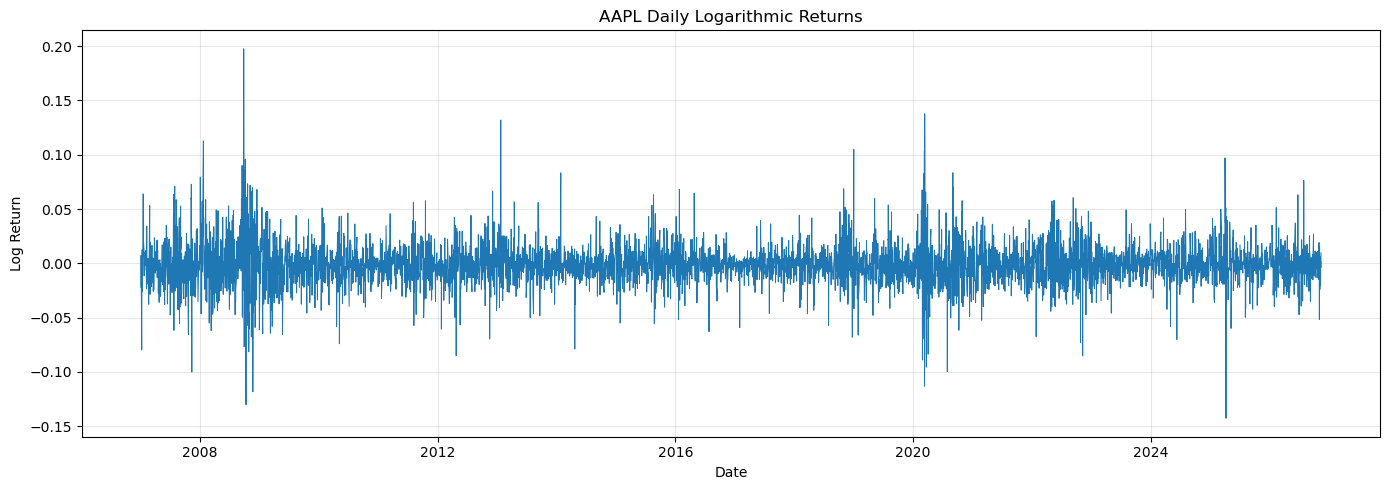

In [25]:
AAPL_daily['datetime']=pd.to_datetime(AAPL_daily['datetime'])
AAPL_intraday['datetime']=pd.to_datetime(AAPL_intraday['datetime'])

plt.figure(figsize=(14, 5))

plt.plot(
    AAPL_daily['datetime'],
    AAPL_daily['log_return'],
    linewidth=0.7
)

plt.title('AAPL Daily Logarithmic Returns')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


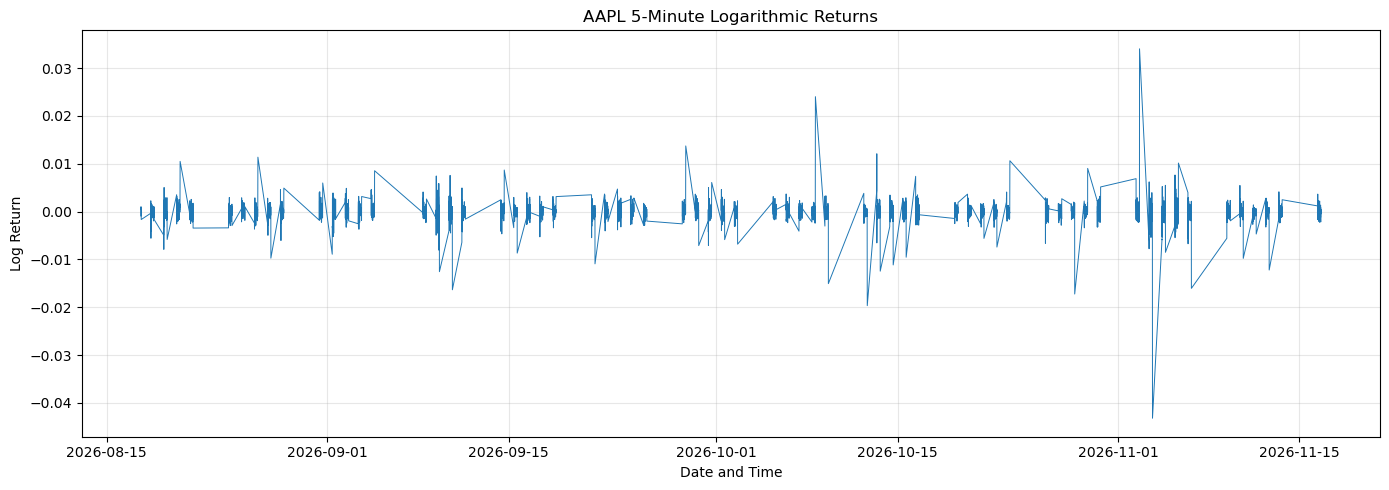

In [26]:

plt.figure(figsize=(14, 5))

plt.plot(
    AAPL_intraday['datetime'],
    AAPL_intraday['log_return'],
    linewidth=0.7
)

plt.title('AAPL 5-Minute Logarithmic Returns')
plt.xlabel('Date and Time')
plt.ylabel('Log Return')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Data Quality and Missing Observations

In [27]:

# Check missing values in both datasets

print("Daily data - Missing values:")
print(AAPL_daily.isnull().sum())

print("\nIntraday data - Missing values:")
print(AAPL_intraday.isnull().sum())


Daily data - Missing values:
datetime      0
open          0
high          0
low           0
close         0
volume        0
return        1
log_return    1
dtype: int64

Intraday data - Missing values:
datetime      0
open          0
high          0
low           0
close         0
volume        0
return        1
log_return    1
dtype: int64


In [28]:

# Compare dataset dimensions

print("Daily observations:", len(AAPL_daily))
print("Intraday observations:", len(AAPL_intraday))

# Compare date ranges

print("Daily date range:")
print(AAPL_daily['datetime'].min(), "to", AAPL_daily['datetime'].max())

print("Intraday date range:")
print(AAPL_intraday['datetime'].min(), "to", AAPL_intraday['datetime'].max())


Daily observations: 5000
Intraday observations: 5000
Daily date range:
2007-01-03 00:00:00 to 2026-11-16 00:00:00
Intraday date range:
2026-08-17 15:20:00 to 2026-11-16 15:55:00
